# M4 — VGG16 multiclasses (sans DA / sans OS)
Adaptation de E4, sur les mêmes partitions d’images. Le test reste intact. Ne pas comparer directement les scores binaires et macro-multiclasses.

In [8]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

tf.keras.utils.set_random_seed(42)
train_df = pd.read_csv("../covid/splits/train.csv")
val_df = pd.read_csv("../covid/splits/validation.csv")
CLASSES = ["COVID", "Normal", "Lung_Opacity", "Viral Pneumonia"]
print("Colonnes :", train_df.columns.tolist())
print("Classes train :", train_df["class"].value_counts())
print("Classes validation :", val_df["class"].value_counts())

Colonnes : ['class', 'filename', 'width', 'height', 'mode', 'mean_intensity', 'contrast', 'filepath', 'target']
Classes train : class
Normal             6495
Lung_Opacity       3895
COVID              2314
Viral Pneumonia     841
Name: count, dtype: int64
Classes validation : class
Normal             1607
Lung_Opacity        977
COVID               579
Viral Pneumonia     224
Name: count, dtype: int64


**Contrôle important :** les valeurs exactes des quatre classes sont lues dans les CSV. La cellule suivante utilise les noms réellement présents, sans deviner les espaces ou underscores.

In [9]:
classes = sorted(train_df["class"].dropna().unique().tolist())
assert len(classes) == 4, f"Attendu 4 classes, obtenu : {classes}"
assert set(val_df["class"].unique()) == set(classes)
assert set(train_df["filepath"]).isdisjoint(set(val_df["filepath"]))
print("Ordre des classes :", classes)

train_gen_df = train_df.copy()
val_gen_df = val_df.copy()
train_gen_df["class"] = train_gen_df["class"].astype(str)
val_gen_df["class"] = val_gen_df["class"].astype(str)

datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
train_generator = datagen.flow_from_dataframe(
    train_gen_df, x_col="filepath", y_col="class", classes=classes,
    target_size=(224,224), color_mode="rgb", class_mode="categorical",
    batch_size=32, shuffle=True, seed=42)
val_generator = datagen.flow_from_dataframe(
    val_gen_df, x_col="filepath", y_col="class", classes=classes,
    target_size=(224,224), color_mode="rgb", class_mode="categorical",
    batch_size=32, shuffle=False)
assert len(train_generator.class_indices) == 4
assert train_generator.class_indices == val_generator.class_indices

Ordre des classes : ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']
Found 13545 validated image filenames belonging to 4 classes.
Found 3387 validated image filenames belonging to 4 classes.


In [3]:
base_model = VGG16(weights="imagenet", include_top=False, input_shape=(224,224,3))
base_model.trainable = False
model_m4 = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(4, activation="softmax")
])
model_m4.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model_m4.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,780,868 (56.38 MB)

 Trainable params: 66,180 (258.52 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [4]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    ModelCheckpoint("M4_VGG16_multiclass_best.keras", monitor="val_loss", save_best_only=True)
]
history_m4 = model_m4.fit(
    train_generator, validation_data=val_generator,
    epochs=5, callbacks=callbacks
)

Epoch 1/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 7115s 17s/step - accuracy: 0.7346 - loss: 0.7711 - val_accuracy: 0.8397 - val_loss: 0.4214
Epoch 2/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 2763s 7s/step - accuracy: 0.8161 - loss: 0.4842 - val_accuracy: 0.8361 - val_loss: 0.4080
Epoch 3/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 2918s 7s/step - accuracy: 0.8421 - loss: 0.4229 - val_accuracy: 0.8595 - val_loss: 0.3495
Epoch 4/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 3178s 7s/step - accuracy: 0.8569 - loss: 0.3847 - val_accuracy: 0.8742 - val_loss: 0.3185
Epoch 5/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 4012s 9s/step - accuracy: 0.8652 - loss: 0.3627 - val_accuracy: 0.8831 - val_loss: 0.3130


In [10]:
#from tensorflow.keras.models import load_model

#model_m4 = load_model("M4_VGG16_multiclass_best.keras")
#print("Modèle chargé avec succès")
#print("Classes en sortie :", model.output_shape[-1])

#récupérartion du modèle déjà entrainé
from tensorflow.keras.models import load_model

model_m4 = load_model("M4_VGG16_multiclass_best.keras")

print("Modèle M4 chargé")
print("Images validation :", val_generator.n)
print("Ordre des classes :", val_generator.class_indices)

assert val_generator.n == 3387
assert val_generator.shuffle is False

Modèle M4 chargé
Images validation : 3387
Ordre des classes : {'COVID': 0, 'Lung_Opacity': 1, 'Normal': 2, 'Viral Pneumonia': 3}


In [5]:
import pandas as pd

pd.DataFrame(history_m4.history).to_csv("M4_history.csv", index=False)
print("Epochs effectuées :", len(history_m4.history["loss"]))

NameError: name 'history_m4' is not defined

## Évaluation sur validation uniquement — après entraînement

106/106 ━━━━━━━━━━━━━━━━━━━━ 1069s 10s/step
                 precision    recall  f1-score   support

          COVID     0.8371    0.8964    0.8657       579
   Lung_Opacity     0.8674    0.8301    0.8483       977
         Normal     0.8993    0.9004    0.8999      1607
Viral Pneumonia     0.9596    0.9554    0.9575       224

       accuracy                         0.8831      3387
      macro avg     0.8909    0.8956    0.8929      3387
   weighted avg     0.8835    0.8831    0.8830      3387



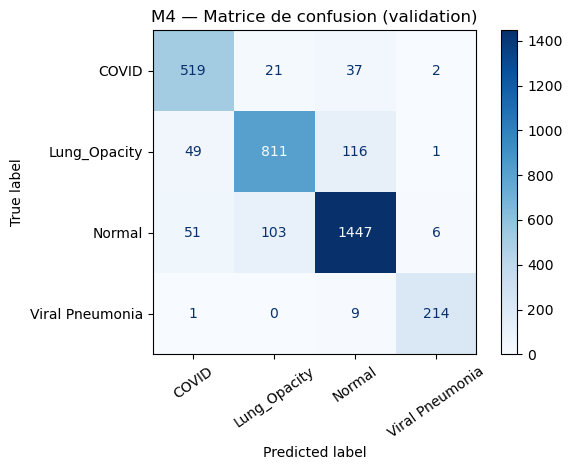

F1 macro : 0.8929
Recall macro : 0.8956
Recall COVID : 0.8964


In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
val_generator.reset()
y_prob = model_m4.predict(val_generator, verbose=1)
y_true = val_generator.classes
y_pred = np.argmax(y_prob, axis=1)
print(classification_report(y_true, y_pred, target_names=classes, digits=4, zero_division=0))
report = classification_report(y_true, y_pred, target_names=classes, output_dict=True, zero_division=0)
pd.DataFrame(report).transpose().to_csv("M4_classification_report.csv")
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes).plot(cmap="Blues", values_format="d", xticks_rotation=35)
plt.title("M4 — Matrice de confusion (validation)")
plt.tight_layout()
plt.savefig("M4_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print("F1 macro :", round(report["macro avg"]["f1-score"], 4))
print("Recall macro :", round(report["macro avg"]["recall"], 4))
print("Recall COVID :", round(report["COVID"]["recall"], 4))

In [12]:
for metric in ["loss", "accuracy"]:
    plt.figure(figsize=(7,4))
    plt.plot(history_m4.history[metric], label="Train")
    plt.plot(history_m4.history[f"val_{metric}"], label="Validation")
    plt.title(f"M4 — {metric}")
    plt.xlabel("Epoch")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"M4_{metric}.png", dpi=150, bbox_inches="tight")
    plt.show()

NameError: name 'history_m4' is not defined

<Figure size 700x400 with 0 Axes>

Époques enregistrées : 5
Colonnes disponibles : ['accuracy', 'loss', 'val_accuracy', 'val_loss']


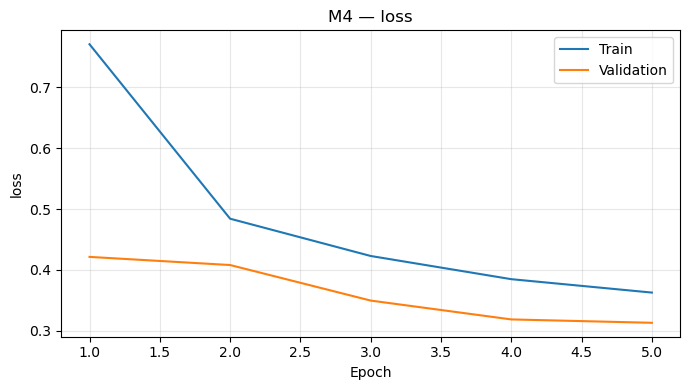

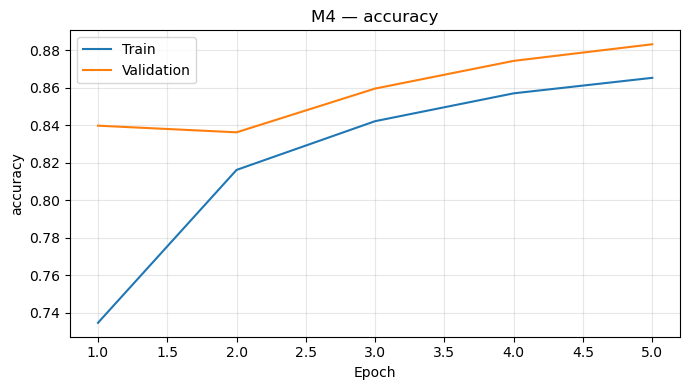

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Récupération de l'historique sauvegardé après l'entraînement
history_df = pd.read_csv("M4_history.csv")

print("Époques enregistrées :", len(history_df))
print("Colonnes disponibles :", history_df.columns.tolist())

# Courbes d'apprentissage
for metric in ["loss", "accuracy"]:
    plt.figure(figsize=(7, 4))

    plt.plot(
        range(1, len(history_df) + 1),
        history_df[metric],
        label="Train"
    )

    plt.plot(
        range(1, len(history_df) + 1),
        history_df[f"val_{metric}"],
        label="Validation"
    )

    plt.title(f"M4 — {metric}")
    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        f"M4_{metric}.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

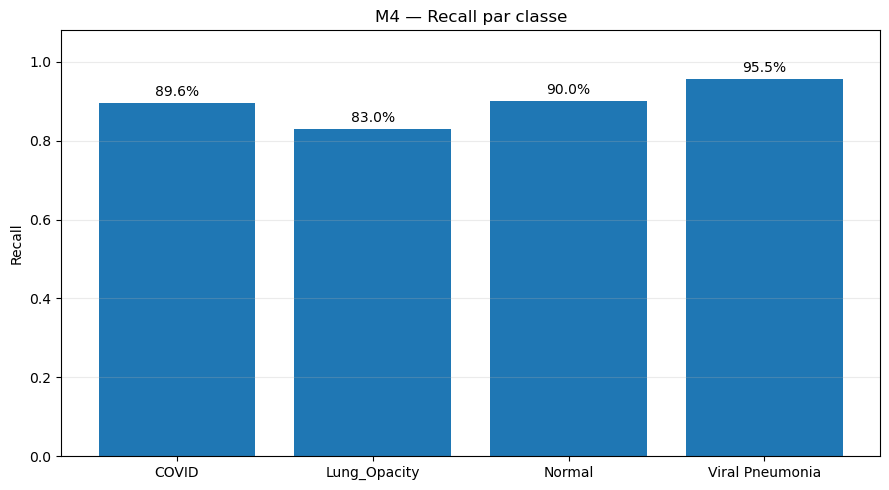

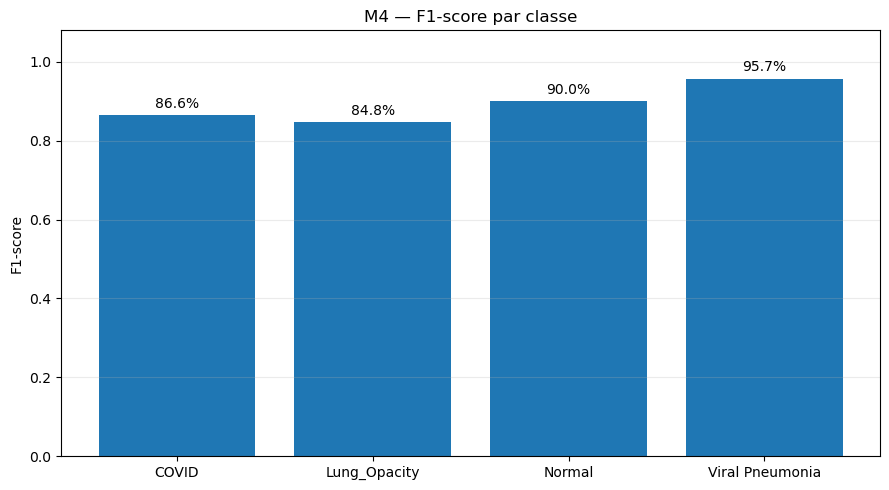

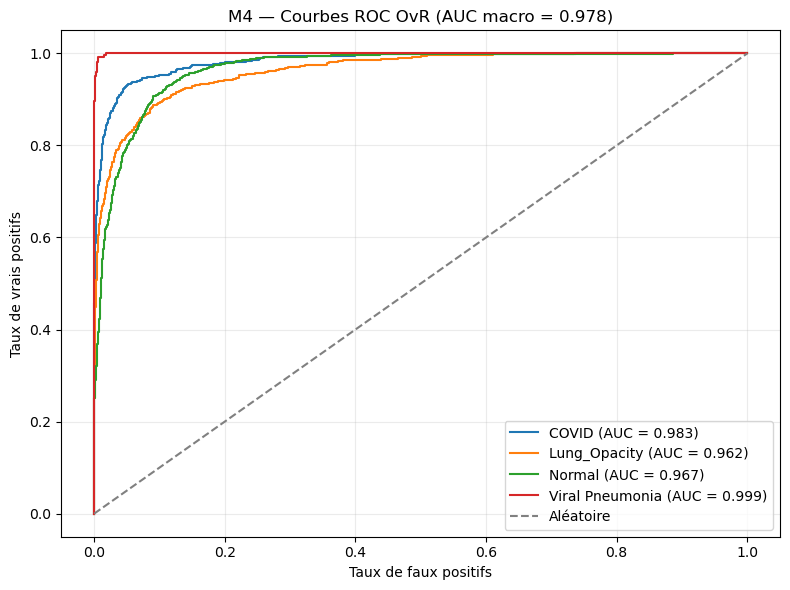

In [15]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_fscore_support,
    roc_curve,
    auc
)

# Classes dans l'ordre du générateur
class_names = [
    name for name, idx in sorted(
        val_generator.class_indices.items(),
        key=lambda item: item[1]
    )
]

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_prob = np.asarray(y_prob)

# Calcul des métriques par classe
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    zero_division=0
)

# --------------------------------------------------
# 1. RECALL : comparaison entre les quatre classes
# --------------------------------------------------

plt.figure(figsize=(9, 5))

bars = plt.bar(class_names, recall)

plt.bar_label(
    bars,
    labels=[f"{v:.1%}" for v in recall],
    padding=3
)

plt.ylim(0, 1.08)
plt.ylabel("Recall")
plt.title("M4 — Recall par classe")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig("M4_recall_par_classe.png", dpi=150)
plt.show()


# --------------------------------------------------
# 2. F1-SCORE : comparaison entre les quatre classes
# --------------------------------------------------

plt.figure(figsize=(9, 5))

bars = plt.bar(class_names, f1)

plt.bar_label(
    bars,
    labels=[f"{v:.1%}" for v in f1],
    padding=3
)

plt.ylim(0, 1.08)
plt.ylabel("F1-score")
plt.title("M4 — F1-score par classe")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig("M4_f1_par_classe.png", dpi=150)
plt.show()


# --------------------------------------------------
# 3. COURBES ROC / AUC MULTICLASSES (OvR)
# --------------------------------------------------

plt.figure(figsize=(8, 6))

auc_scores = []

for idx, class_name in enumerate(class_names):
    y_binary = (y_true == idx).astype(int)

    fpr, tpr, _ = roc_curve(y_binary, y_prob[:, idx])
    class_auc = auc(fpr, tpr)
    auc_scores.append(class_auc)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {class_auc:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    "--",
    color="gray",
    label="Aléatoire"
)

plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs")
plt.title(
    f"M4 — Courbes ROC OvR "
    f"(AUC macro = {np.mean(auc_scores):.3f})"
)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig("M4_ROC_multiclasse.png", dpi=150)
plt.show()